# Five-fold results

These numbers are the saved run in `results/fold_metrics.json`. Epoch-by-epoch validation MAE is in `results/experiment.log`.

The published Table 6 MAE values are shown beside this run. Top-10 F1, MAP, and MRR are not comparable to the paper: each test user is ranked against all 1,850 hotels, and a user typically has one held-out hotel, so that hotel rarely enters the top 10. Fraction of concordant pairs only orders hotels that have a test label.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from src.data import CRITERIA
payload = json.loads((ROOT / 'results' / 'fold_metrics.json').read_text())
summary = payload['summary']
print(payload['n_ratings'], 'ratings,', payload['n_users'], 'users,', payload['n_items'], 'hotels')
print('device', payload['assumptions']['device'])
print('overfit drop', round(payload['overfit']['drop'], 3))


81085 ratings, 72119 users, 1850 hotels
device cuda
overfit drop 2.535


## Table 5 — criteria MAE

In [2]:
PAPER_CRITERIA = {
    'value': (0.8195, 0.0082),
    'rooms': (0.7612, 0.0082),
    'location': (0.6581, 0.0077),
    'cleanliness': (0.6324, 0.0112),
    'checkin': (0.7582, 0.0143),
    'service': (0.7401, 0.0103),
    'business': (0.8774, 0.0053),
    'mean': (0.7495, 0.0073),
}
LABELS = {
    'value': 'Value',
    'rooms': 'Rooms',
    'location': 'Location',
    'cleanliness': 'Cleanliness',
    'checkin': 'Check in / front desk',
    'service': 'Service',
    'business': 'Business service',
    'mean': 'Mean',
}

def pm(stats):
    return f"{stats['mean']:.4f} ± {stats['std']:.4f}"

print(f'{'aspect':<24} {'this run':>18} {'paper':>18}')
for name in list(CRITERIA) + ['mean']:
    paper_mean, paper_std = PAPER_CRITERIA[name]
    paper = f'{paper_mean:.4f} ± {paper_std:.4f}'
    print(f'{LABELS[name]:<24} {pm(summary["criteria_mae"][name]):>18} {paper:>18}')


aspect                             this run              paper
Value                       0.8449 ± 0.0080    0.8195 ± 0.0082
Rooms                       0.7941 ± 0.0042    0.7612 ± 0.0082
Location                    0.6897 ± 0.0133    0.6581 ± 0.0077
Cleanliness                 0.6729 ± 0.0057    0.6324 ± 0.0112
Check in / front desk       0.7905 ± 0.0057    0.7582 ± 0.0143
Service                     0.7759 ± 0.0078    0.7401 ± 0.0103
Business service            0.8987 ± 0.0064    0.8774 ± 0.0053
Mean                        0.7810 ± 0.0042    0.7495 ± 0.0073


## Table 6 — overall rating

In [3]:
PAPER_MAE = {
    'svd': (0.8071, 0.0043),
    'svdpp': (0.8222, 0.0071),
    'slope_one': (0.9160, 0.0053),
    'baseline': (0.8094, 0.0019),
    'knn': (0.8115, 0.0041),
    'single_dnn': (0.7855, 0.0153),
    'ours': (0.7552, 0.0050),
}
ORDER = [
    ('ours', 'Our'),
    ('single_dnn', 'Single DNN'),
    ('svd', 'SVD'),
    ('svdpp', 'SVD++'),
    ('slope_one', 'Slope One'),
    ('baseline', 'Baseline'),
    ('knn', 'KNN with baseline'),
]
METRICS = ['mae', 'f1', 'f2', 'fcp', 'map', 'mrr']

print(f'{'method':<20} {'MAE':>18} {'paper MAE':>18} {'FCP':>18}')
for key, label in ORDER:
    paper_mean, paper_std = PAPER_MAE[key]
    paper = f'{paper_mean:.4f} ± {paper_std:.4f}'
    row = summary['methods'][key]
    print(f'{label:<20} {pm(row["mae"]):>18} {paper:>18} {pm(row["fcp"]):>18}')
print()
print('Top-10 metrics for the two-stage model')
for metric in METRICS:
    print(f'{metric:<6} {pm(summary["methods"]["ours"][metric])}')


method                              MAE          paper MAE                FCP
Our                     0.7715 ± 0.0146    0.7552 ± 0.0050    0.6854 ± 0.0176
Single DNN              0.7817 ± 0.0057    0.7855 ± 0.0153    0.6674 ± 0.0192
SVD                     0.8055 ± 0.0034    0.8071 ± 0.0043    0.6804 ± 0.0136
SVD++                   0.8216 ± 0.0035    0.8222 ± 0.0071    0.6838 ± 0.0282
Slope One               0.8924 ± 0.0059    0.9160 ± 0.0053    0.5127 ± 0.1056
Baseline                0.8093 ± 0.0031    0.8094 ± 0.0019    0.6853 ± 0.0154
KNN with baseline       0.8100 ± 0.0031    0.8115 ± 0.0041    0.6823 ± 0.0187

Top-10 metrics for the two-stage model
mae    0.7715 ± 0.0146
f1     0.0013 ± 0.0003
f2     0.0025 ± 0.0005
fcp    0.6854 ± 0.0176
map    0.0019 ± 0.0003
mrr    0.0020 ± 0.0003


Re-run the full comparison with:

`conda run -n rds python -m src.experiment`

## Validation curves

Validation MAE from the latest logged run. The first block of epochs, before fold 0, is the 48-row overfit check and is left off these axes. Early stopping ends a curve when validation MAE stops improving.

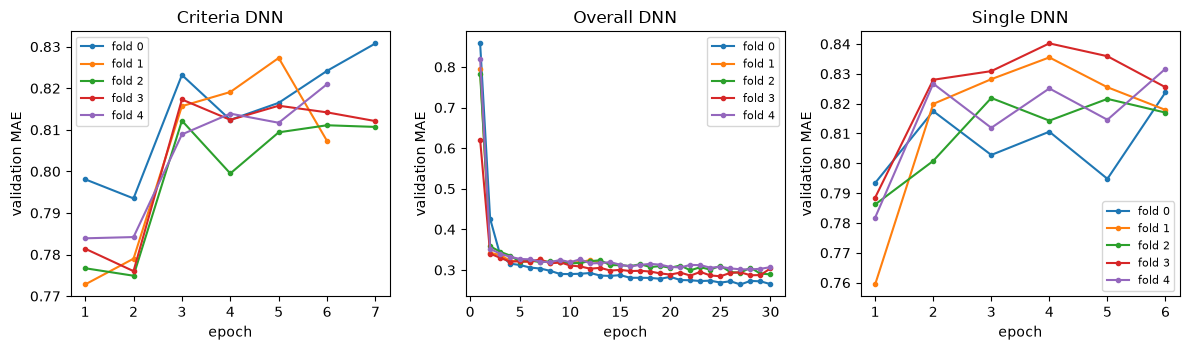

In [4]:
import re
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

figures = ROOT / 'results' / 'figures'
figures.mkdir(parents=True, exist_ok=True)
text = (ROOT / 'results' / 'experiment.log').read_text()
body = text[text.rfind('logging to'):]
curves = defaultdict(dict)
current = None
fold = None
for line in body.splitlines():
    header = re.search(r'fold (\d+): (criteria DNN|overall DNN|single DNN)', line)
    if header:
        fold = int(header.group(1))
        label = header.group(2)
        current = 'criteria' if label.startswith('criteria') else 'overall' if label.startswith('overall') else 'single'
        curves[current][fold] = []
        continue
    point = re.search(r'epoch (\d+)\s+val_mae ([0-9.]+)', line)
    if point and current is not None:
        curves[current][fold].append(float(point.group(2)))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
titles = {'criteria': 'Criteria DNN', 'overall': 'Overall DNN', 'single': 'Single DNN'}
for ax, key in zip(axes, ('criteria', 'overall', 'single')):
    for fold_id, series in sorted(curves[key].items()):
        ax.plot(range(1, len(series) + 1), series, marker='o', ms=3, label=f'fold {fold_id}')
    ax.set_title(titles[key])
    ax.set_xlabel('epoch')
    ax.set_ylabel('validation MAE')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / 'validation_mae.png', dpi=150)
plt.show()


## MAE against the paper

Bars are the five-fold mean. The paper did not publish per-criterion standard deviations on the same plot; both means are shown.

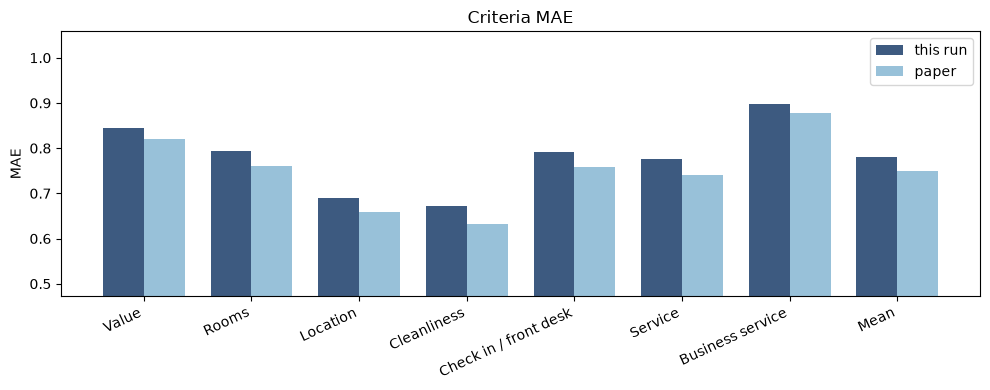

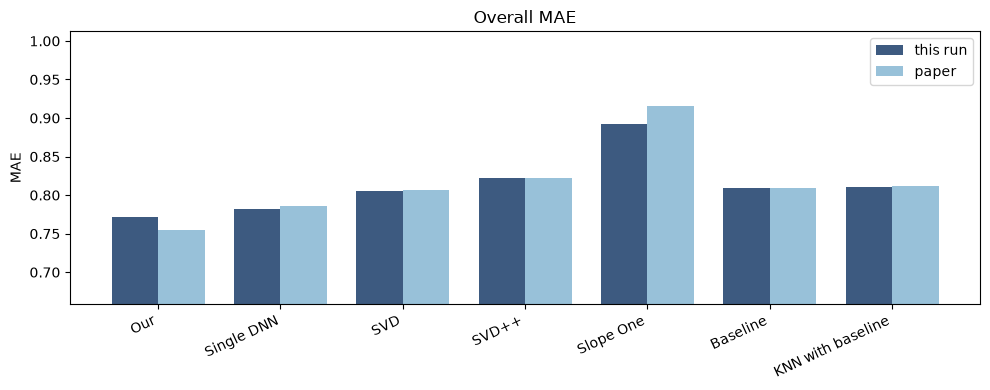

In [5]:
def grouped_bars(labels, ours, paper, path, title):
    x = np.arange(len(labels))
    width = 0.38
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - width / 2, ours, width, label='this run', color='#3d5a80')
    ax.bar(x + width / 2, paper, width, label='paper', color='#98c1d9')
    ax.set_xticks(x, labels, rotation=25, ha='right')
    low = min(min(ours), min(paper))
    high = max(max(ours), max(paper))
    pad = max((high - low) * 0.6, 0.02)
    ax.set_ylim(low - pad, high + pad)
    ax.set_ylabel('MAE')
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()

criteria_labels = [LABELS[name] for name in list(CRITERIA) + ['mean']]
grouped_bars(
    criteria_labels,
    [summary['criteria_mae'][name]['mean'] for name in list(CRITERIA) + ['mean']],
    [PAPER_CRITERIA[name][0] for name in list(CRITERIA) + ['mean']],
    figures / 'criteria_mae.png',
    'Criteria MAE',
)
method_keys = [key for key, _label in ORDER]
grouped_bars(
    [label for _key, label in ORDER],
    [summary['methods'][key]['mae']['mean'] for key in method_keys],
    [PAPER_MAE[key][0] for key in method_keys],
    figures / 'overall_mae.png',
    'Overall MAE',
)
